In [46]:
import pandas as pd

df = pd.read_excel(
    "Alumni_Fundraising_Cleaned_1000 (3).xlsx",
    sheet_name="Model Input"
)

print(df.shape)
df.head()

(1000, 6)


,aff_total,coresex,coreprefyr,Degree,Major,major_gift
0,24,M,1988,BBA,Accounting,0
1,26,F,2012,BA,English Language and Literature,1
2,82,F,1972,BA,Political Science,1
3,2,F,2000,MED,General Education,0
4,4,M,2005,BA,English Language and Literature,0


## 1. Univariate Analysis

This section examines the distribution of the target variable and each predictor to identify class imbalance, skew, unusual values, and important patterns in the data.

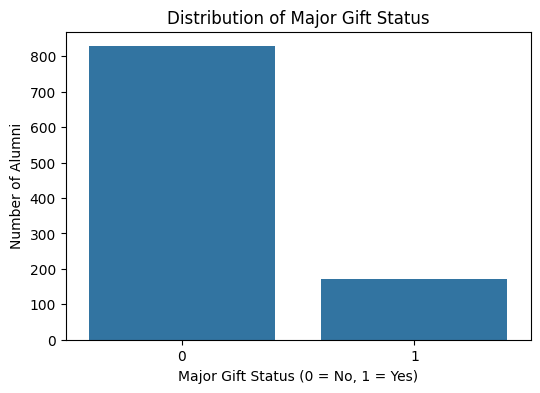

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="major_gift"
)

plt.title("Distribution of Major Gift Status")
plt.xlabel("Major Gift Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Alumni")

plt.show()

The target distribution shows that fewer alumni made a major gift than did not make a major gift. This indicates that the target classes are imbalanced, which will be important when choosing evaluation metrics for the classification model.

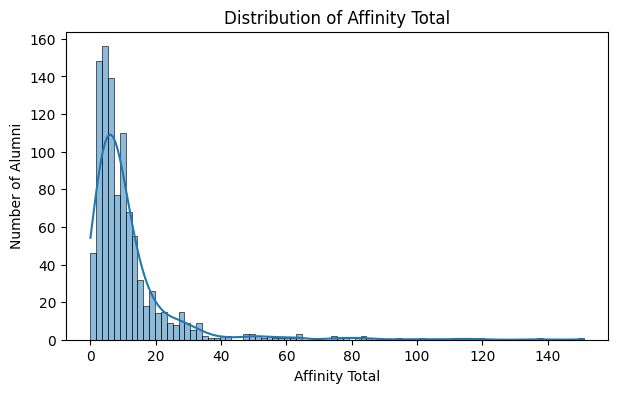

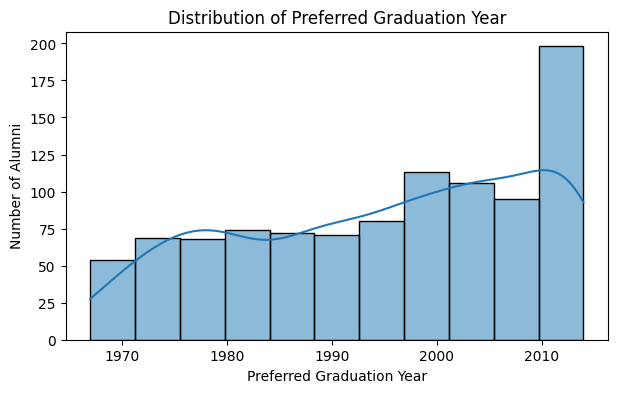

In [72]:
numeric_cols = ["aff_total", "coreprefyr"]

labels = {
    "aff_total": "Affinity Total",
    "coreprefyr": "Preferred Graduation Year"
}

for col in numeric_cols:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f"Distribution of {labels[col]}")
    plt.xlabel(labels[col])
    plt.ylabel("Number of Alumni")

    plt.show()

The aff total distribution is strongly right-skewed. Most alumni have lower values, mainly below about 20, while a small number have much higher values reaching over 100. These high values should be checked as possible outliers, but they may represent real alumni with unusually high activity.               


Because aff_total is heavily skewed, I may consider scaling or transforming it during preprocessing in M3.


The coreprefyr distribution shows more alumni in the later years, especially around 2000–2013. This means the data is not evenly distributed across years, so year may be useful when predicting whether an alumnus makes a major gift.


In [51]:
categorical_cols = ["coresex", "Degree", "Major"]

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


coresex
coresex
F    508
M    492
Name: count, dtype: int64

Degree
Degree
BS      400
BBA     193
BA      132
MED      75
MBA      45
MS       25
MPA      24
BSN      21
MSA      11
MSW      11
MSN      10
MPAS      8
BSW       7
MST       7
BSE       7
BPH       5
DPT       3
BFA       3
DNP       2
PMCE      2
MA        2
BME       2
BAS       1
PBCE      1
MHS       1
EDS       1
PRCE      1
Name: count, dtype: int64

Major
Major
Accounting                        60
Business General                  53
Management                        46
General Education                 44
Marketing                         43
                                  ..
Radiation Therapy                  1
Women & Gender Studies             1
Studio Art                         1
Occupational Safety/Health Mgt     1
Medical Laboratory Science         1
Name: count, Length: 111, dtype: int64


The coresex distribution is almost evenly split between female and male alumni. This means sex is fairly balanced in the dataset and should not create a major imbalance problem during modeling.

The Degree distribution is uneven. BS is the most common degree, followed by BBA and BA, while many other degree types appear only a few times. In M3, I may need to combine very rare degree categories so the model does not overfit to categories with very few alumni.

The Major variable has many different categories, and several majors have only a small number of alumni. This could make the feature too detailed for modeling, so I may group rare majors into an "Other" category during preprocessing.


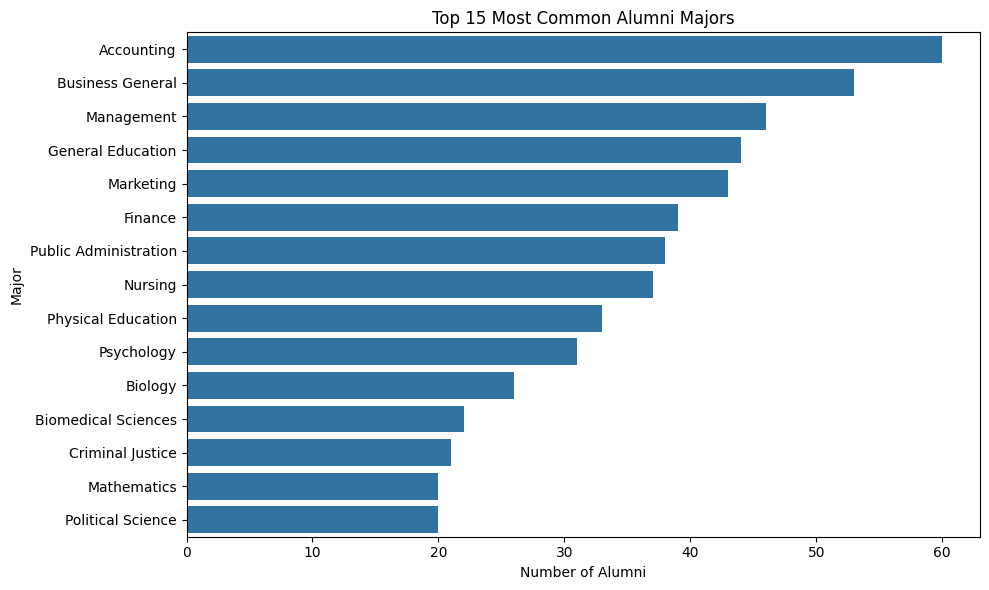

In [52]:
top_majors = df["Major"].value_counts().head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_majors.values,
    y=top_majors.index
)

plt.title("Top 15 Most Common Alumni Majors")
plt.xlabel("Number of Alumni")
plt.ylabel("Major")

plt.tight_layout()
plt.show()

The most common majors contain much more data than many of the less common majors. Because several majors occur very rarely, I may group rare majors together during preprocessing to make the feature easier for the model to use.


In [53]:
print(df["major_gift"].value_counts())

print("\nPercentages:")
print(df["major_gift"].value_counts(normalize=True) * 100)

major_gift
0    828
1    172
Name: count, dtype: int64

Percentages:
major_gift
0    82.8
1    17.2
Name: proportion, dtype: float64


The major_gift target is imbalanced because 82.8% of alumni did not make a major gift, while only 17.2% did. This matters because a model could get high accuracy just by predicting the majority class, so I should use metrics such as recall, precision, or F1 score instead of relying only on accuracy.


## 2. Missingness

This section checks how much data is missing from each column and whether missing values are related to the target variable.

In [55]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percent": (df.isnull().mean() * 100).round(2)
})

missing

,Missing Count,Missing Percent
aff_total,0,0.0
coresex,0,0.0
coreprefyr,0,0.0
Degree,0,0.0
Major,0,0.0
major_gift,0,0.0


In [56]:
df.isnull().sum().sum()

np.int64(0)

Missing Count = 0
Missing Percent = 0.0

There are no missing values in any of the columns in this dataset. Because there is no missing data, there is no missingness pattern to compare with the target variable. No imputation or removal of rows will be needed for missing values in M3.

## 3. Outliers

This section checks the numeric variables for unusually high or low values and determines whether they appear to be data errors or real extreme values.

In [57]:
numeric_cols = ["aff_total", "coreprefyr"]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"{col}")
    print(f"Lower bound: {lower_bound}")
    print(f"Upper bound: {upper_bound}")
    print(f"Number of outliers: {len(outliers)}")
    print()

aff_total
Lower bound: -9.5
Upper bound: 26.5
Number of outliers: 79

coreprefyr
Lower bound: 1947.0
Upper bound: 2043.0
Number of outliers: 0



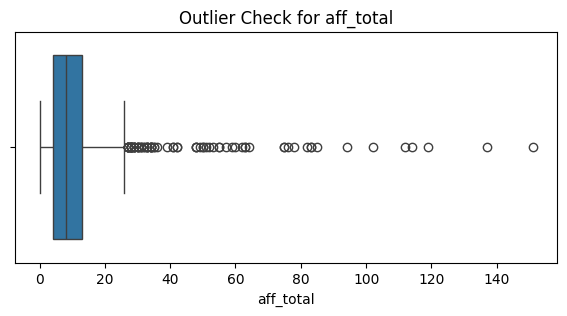

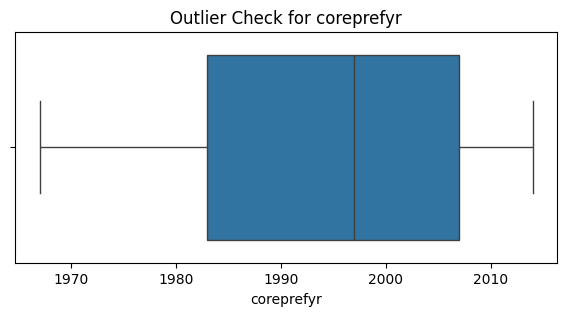

In [58]:
for col in numeric_cols:
    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Outlier Check for {col}")
    plt.xlabel(col)

    plt.show()

The aff_total variable has 79 statistical outliers, with values above 26.5 flagged by the IQR method. These values appear to be real extreme observations rather than data errors because higher affiliation totals are possible for some alumni. I will keep these values for now, but I may use scaling or a transformation in M3 because the variable is strongly right-skewed.

The coreprefyr variable has no outliers based on the IQR method. The years fall within a reasonable range, so I do not need to remove or adjust any values for this feature.


## 4. Bivariate Analysis

This section compares each predictor with the target variable, `major_gift`, to identify which features may be useful for predicting whether an alumnus makes a major gift.

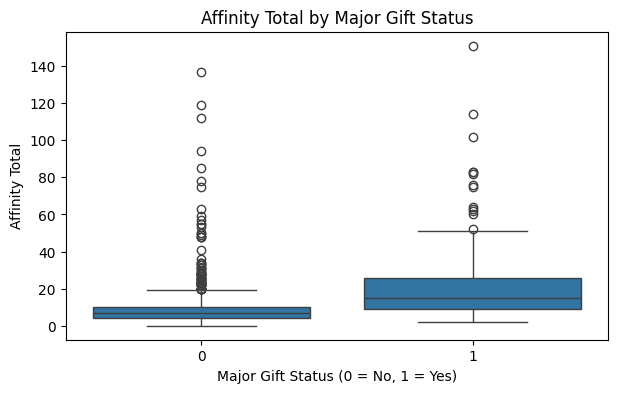

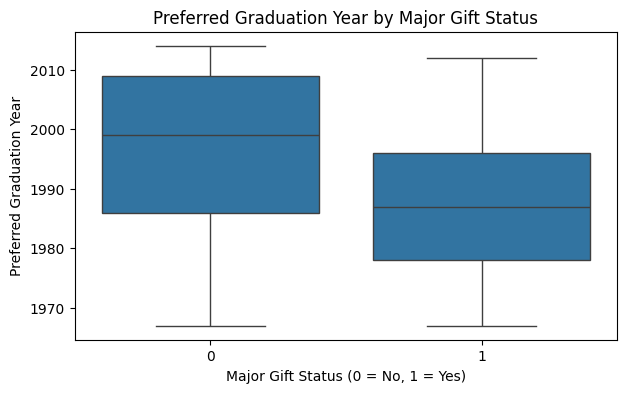

In [73]:
numeric_cols = ["aff_total", "coreprefyr"]

labels = {
    "aff_total": "Affinity Total",
    "coreprefyr": "Preferred Graduation Year"
}

for col in numeric_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="major_gift",
        y=col
    )

    plt.title(f"{labels[col]} by Major Gift Status")
    plt.xlabel("Major Gift Status (0 = No, 1 = Yes)")
    plt.ylabel(labels[col])

    plt.show()

In [60]:
df.groupby("major_gift")[["aff_total", "coreprefyr"]].mean().round(2)

,aff_total,coreprefyr
major_gift,,
0,9.48,1996.67
1,20.76,1986.83


Alumni who made a major gift had a much higher average aff_total of 20.76 compared with 9.48 for alumni who did not make a major gift. This suggests that aff_total may be an important predictor of major giving and should be kept for modeling.
Alumni who made a major gift had an earlier average coreprefyr of 1986.83 compared with 1996.67 for alumni who did not make a major gift. This suggests that alumni from earlier years may be more likely to make a major gift, so coreprefyr may also be useful for prediction.


In [61]:
coresex_results = pd.crosstab(
    df["coresex"],
    df["major_gift"],
    normalize="index"
) * 100

coresex_results.round(2)

major_gift,0,1
coresex,,
F,85.63,14.37
M,79.88,20.12


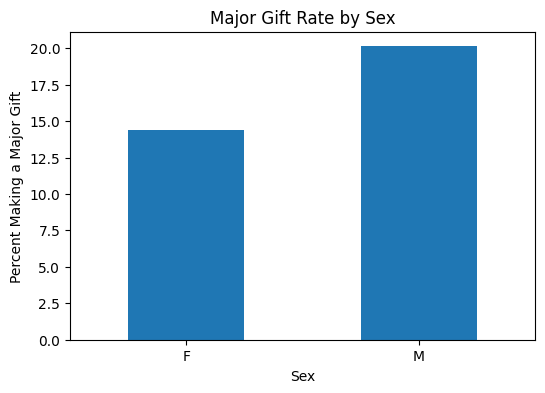

In [62]:
gift_rate_sex = df.groupby("coresex")["major_gift"].mean() * 100

plt.figure(figsize=(6, 4))
gift_rate_sex.plot(kind="bar")

plt.title("Major Gift Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Percent Making a Major Gift")
plt.xticks(rotation=0)

plt.show()

Male alumni had a higher major gift rate at 20.12% compared with 14.37% for female alumni. This suggests that coresex may have some relationship with major gift status and could be useful as a predictor in the model.


In [63]:
degree_results = df.groupby("Degree").agg(
    Alumni_Count=("major_gift", "count"),
    Major_Gift_Rate=("major_gift", "mean")
)

degree_results["Major_Gift_Rate"] *= 100

degree_results.sort_values(
    "Alumni_Count",
    ascending=False
).round(2)

,Alumni_Count,Major_Gift_Rate
Degree,,
BS,400,15.00
BBA,193,23.83
BA,132,15.15
MED,75,16.00
MBA,45,28.89
MS,25,4.00
MPA,24,16.67
BSN,21,9.52
MSA,11,9.09


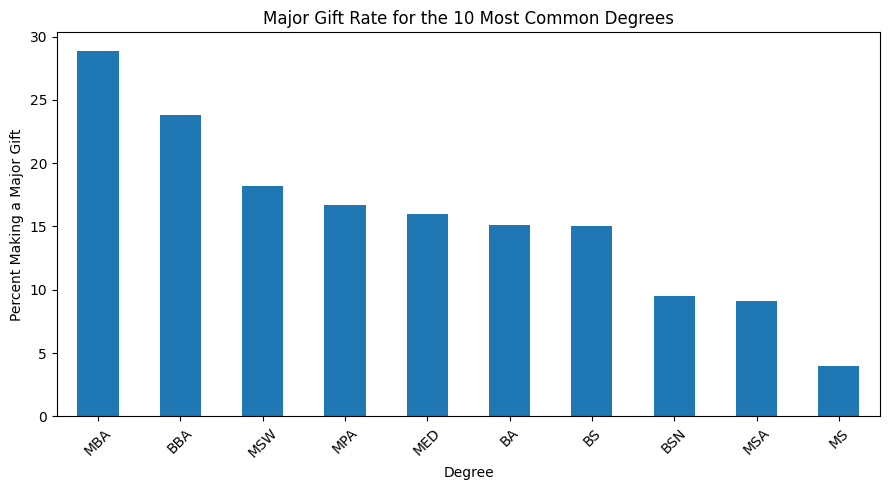

In [64]:
top_degrees = df["Degree"].value_counts().head(10).index

degree_plot = (
    df[df["Degree"].isin(top_degrees)]
    .groupby("Degree")["major_gift"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(9, 5))
degree_plot.plot(kind="bar")

plt.title("Major Gift Rate for the 10 Most Common Degrees")
plt.xlabel("Degree")
plt.ylabel("Percent Making a Major Gift")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Among the 10 most common degrees, MBA had the highest major gift rate at 28.89%, followed by BBA at 23.83%. MS had the lowest rate at 4.00%. This suggests that degree type may be related to major giving and could be useful in the model.


Some degree categories have only one or two alumni, so their gift rates can be misleading. In M3, I may combine very rare degree categories into an "Other" group before modeling.


In [65]:
major_results = df.groupby("Major").agg(
    Alumni_Count=("major_gift", "count"),
    Major_Gift_Rate=("major_gift", "mean")
)

major_results["Major_Gift_Rate"] *= 100

major_results.sort_values(
    "Alumni_Count",
    ascending=False
).round(2)

,Alumni_Count,Major_Gift_Rate
Major,,
Accounting,60,25.00
Business General,53,24.53
Management,46,19.57
General Education,44,22.73
Marketing,43,30.23
...,...,...
Radiation Therapy,1,0.00
Studio Art,1,0.00
Social Services,1,0.00


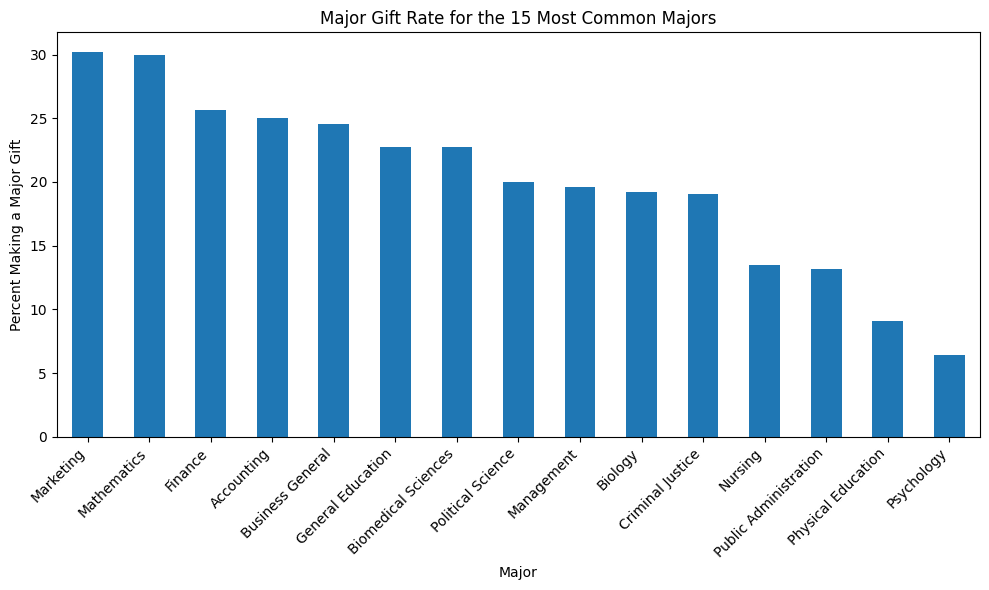

In [66]:
top_majors = df["Major"].value_counts().head(15).index

major_plot = (
    df[df["Major"].isin(top_majors)]
    .groupby("Major")["major_gift"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 6))
major_plot.plot(kind="bar")

plt.title("Major Gift Rate for the 15 Most Common Majors")
plt.xlabel("Major")
plt.ylabel("Percent Making a Major Gift")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Among the 15 most common majors, Marketing and Mathematics had the highest major gift rates at about 30%, while Psychology and Physical Education had some of the lowest rates. This suggests that a person's major may be related to whether they make a major gift.


Since many majors only have a small number of alumni, I may combine rare majors into an "Other" category in M3 so the model does not overfit to very small groups.


## 5. Multicollinearity

This section checks for strong correlations between numeric predictors. Feature pairs with a correlation above 0.80 may create multicollinearity problems in linear models.

In [68]:
corr = df[["aff_total", "coreprefyr"]].corr()

corr

,aff_total,coreprefyr
aff_total,1.000000,-0.244344
coreprefyr,-0.244344,1.000000


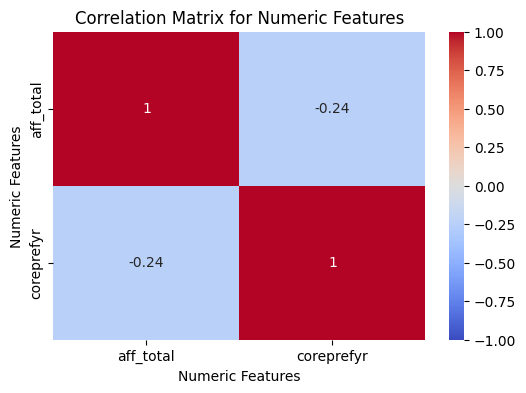

In [69]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix for Numeric Features")
plt.xlabel("Numeric Features")
plt.ylabel("Numeric Features")

plt.show()

The correlation between aff_total and coreprefyr is -0.244, which is a weak negative relationship. Since the absolute correlation is far below 0.80, there is no evidence of high multicollinearity between these numeric predictors, so both can remain in the model.

In [70]:
correlation_value = corr.loc["aff_total", "coreprefyr"]

print("Correlation between aff_total and coreprefyr:", round(correlation_value, 3))

if abs(correlation_value) > 0.80:
    print("This pair has high multicollinearity.")
else:
    print("This pair does not have high multicollinearity.")

Correlation between aff_total and coreprefyr: -0.244
This pair does not have high multicollinearity.


## 6. Leakage Check

This section checks whether any feature contains information that would not be available at prediction time or directly reveals the target.

In [71]:
print(df.columns.tolist())

['aff_total', 'coresex', 'coreprefyr', 'Degree', 'Major', 'major_gift']


I checked the predictors for information that could reveal the target before prediction. The original dataset included fy14, which was used to create major_gift, so using fy14 as a predictor would cause direct target leakage. I excluded coreid because it is only an identifier. I also excluded donor because it has the same value for every record and would not provide useful information to the model. The remaining predictors do not directly reveal the target, so I found no obvious leakage in the final model input.

## 7. Metric Commitment

As discussed in M1, false negatives are more costly for this problem because they could cause the fundraising team to miss an alumnus who would actually make a major gift. Therefore, the main metric I will optimize is recall for the major gift class (major_gift = 1). A false negative would mean the model predicts that an alumnus will not make a major gift when they actually would. Since only 17.2% of the alumni are in the major gift class, accuracy alone could be misleading. I will focus on recall while also looking at precision, F1 score, and the confusion matrix to make sure the model performs reasonably overall.

## 8. Five Findings

1. The target is imbalanced, with 82.8% non-major gifts and 17.2% major gifts, so I will use class-aware evaluation metrics such as recall and F1 score instead of relying only on accuracy.

2. `aff_total` is strongly right-skewed and contains 79 high outliers that appear to be real values, so I will keep them and consider scaling or transforming this feature in M3.

3. Alumni who made a major gift had a higher average `aff_total` of 20.76 compared with 9.48 for non-major-gift alumni, so I will keep `aff_total` as an important predictor.

4. `Degree` and `Major` contain several categories with very few alumni, so I will consider grouping rare categories into an "Other" category before encoding them for the model.

5. `fy14` was used to create the `major_gift` target, so it will remain excluded from the model to prevent target leakage.